<a href="https://colab.research.google.com/github/mdashfaq895/Banking_Customer_EDA/blob/main/Banking_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [58]:
df=pd.read_csv("Banking.csv")
df.head(5)

,Client ID,Name,Age,Location ID,Joined Bank,Banking Contact,Nationality,Occupation,Fee Structure,Loyalty Classification,...,Bank Deposits,Checking Accounts,Saving Accounts,Foreign Currency Account,Business Lending,Properties Owned,Risk Weighting,BRId,GenderId,IAId
0,IND81288,Raymond Mills,24,34324,06-05-2019,Anthony Torres,American,Safety Technician IV,High,Jade,...,1485828.64,603617.88,607332.46,12249.96,1134475.30,1,2,1,1,1
1,IND65833,Julia Spencer,23,42205,10-12-2001,Jonathan Hawkins,African,Software Consultant,High,Jade,...,641482.79,229521.37,344635.16,61162.31,2000526.10,1,3,2,1,2
2,IND47499,Stephen Murray,27,7314,25-01-2010,Anthony Berry,European,Help Desk Operator,High,Gold,...,1033401.59,652674.69,203054.35,79071.78,548137.58,1,3,3,2,3
3,IND72498,Virginia Garza,40,34594,28-03-2019,Steve Diaz,American,Geologist II,Mid,Silver,...,1048157.49,1048157.49,234685.02,57513.65,1148402.29,0,4,4,1,4
4,IND60181,Melissa Sanders,46,41269,20-07-2012,Shawn Long,American,Assistant Professor,Mid,Platinum,...,487782.53,446644.25,128351.45,30012.14,1674412.12,0,3,1,2,5


In [59]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Client ID                 3000 non-null   object 
 1   Name                      3000 non-null   object 
 2   Age                       3000 non-null   int64  
 3   Location ID               3000 non-null   int64  
 4   Joined Bank               3000 non-null   object 
 5   Banking Contact           3000 non-null   object 
 6   Nationality               3000 non-null   object 
 7   Occupation                3000 non-null   object 
 8   Fee Structure             3000 non-null   object 
 9   Loyalty Classification    3000 non-null   object 
 10  Estimated Income          3000 non-null   float64
 11  Superannuation Savings    3000 non-null   float64
 12  Amount of Credit Cards    3000 non-null   int64  
 13  Credit Card Balance       3000 non-null   float64
 14  Bank Loa

,Age,Location ID,Estimated Income,Superannuation Savings,Amount of Credit Cards,Credit Card Balance,Bank Loans,Bank Deposits,Checking Accounts,Saving Accounts,Foreign Currency Account,Business Lending,Properties Owned,Risk Weighting,BRId,GenderId,IAId
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3.000000e+03,3.000000e+03,3.000000e+03,3.000000e+03,3000.000000,3.000000e+03,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,51.039667,21563.323000,171305.034263,25531.599673,1.463667,3176.206943,5.913862e+05,6.715602e+05,3.210929e+05,2.329084e+05,29883.529993,8.667598e+05,1.518667,2.249333,2.559333,1.504000,10.425333
std,19.854760,12462.273017,111935.808209,16259.950770,0.676387,2497.094709,4.575570e+05,6.457169e+05,2.820796e+05,2.300078e+05,23109.924010,6.412303e+05,1.102145,1.131191,1.007713,0.500067,5.988242
min,17.000000,12.000000,15919.480000,1482.030000,1.000000,1.170000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,45.000000,0.000000e+00,0.000000,1.000000,1.000000,1.000000,1.000000
25%,34.000000,10803.500000,82906.595000,12513.775000,1.000000,1236.630000,2.396281e+05,2.044004e+05,1.199475e+05,7.479440e+04,11916.542500,3.748251e+05,1.000000,1.000000,2.000000,1.000000,5.000000
50%,51.000000,21129.500000,142313.480000,22357.355000,1.000000,2560.805000,4.797934e+05,4.633165e+05,2.428157e+05,1.640866e+05,24341.190000,7.113147e+05,2.000000,2.000000,3.000000,2.000000,10.000000
75%,69.000000,32054.500000,242290.305000,35464.740000,2.000000,4522.632500,8.258130e+05,9.427546e+05,4.348749e+05,3.155750e+05,41966.392500,1.185110e+06,2.000000,3.000000,3.000000,2.000000,15.000000
max,85.000000,43369.000000,522330.260000,75963.900000,3.000000,13991.990000,2.667557e+06,3.890598e+06,1.969923e+06,1.724118e+06,124704.870000,3.825962e+06,3.000000,5.000000,4.000000,2.000000,22.000000


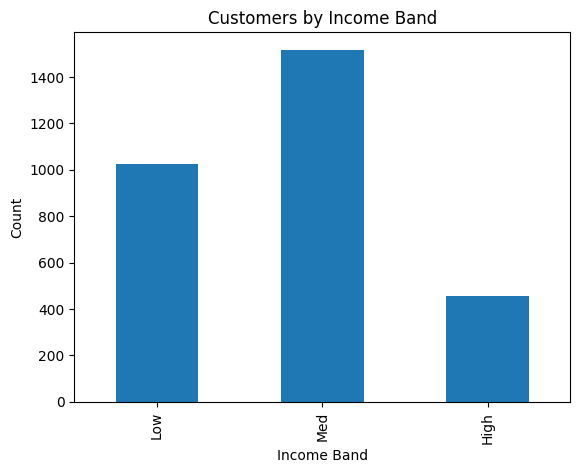

In [60]:
# Income Band

bins = [0, 100000, 300000, float('inf')]
labels = ['Low', 'Med', 'High']
df['Income Band'] = pd.cut(df['Estimated Income'],bins = bins, labels=labels, right=False)
df['Income Band'].value_counts().reindex(labels).plot(kind='bar')
plt.title('Customers by Income Band')
plt.xlabel('Income Band')
plt.ylabel('Count')
plt.show()

In [61]:
# Examine the distribution of unique categories in each column
categorical_cols = ["BRId", "GenderId", "IAId", "Nationality",
                    "Occupation", "Fee Structure", "Loyalty Classification",
                    "Properties Owned", "Risk Weighting", "Income Band"]

for col in categorical_cols:
  print(f"Value Counts for '{col}':")
  display(df[col].value_counts())
  print()

Value Counts for 'BRId':


,count
BRId,
3,1352
1,660
2,495
4,493



Value Counts for 'GenderId':


,count
GenderId,
2,1512
1,1488



Value Counts for 'IAId':


...

,count
Properties Owned,
2,777
1,776
3,742
0,705



Value Counts for 'Risk Weighting':


,count
Risk Weighting,
2,1222
1,836
3,460
4,322
5,160



Value Counts for 'Income Band':


,count
Income Band,
Med,1517
Low,1027
High,456


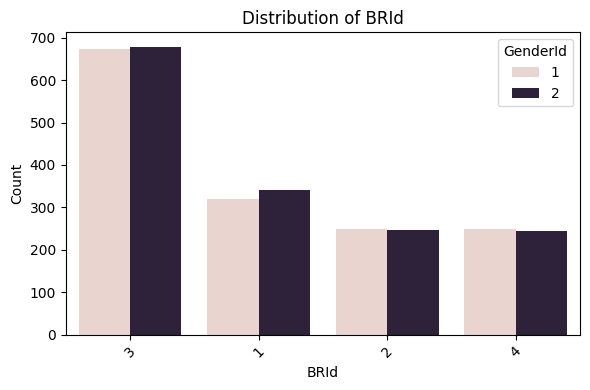

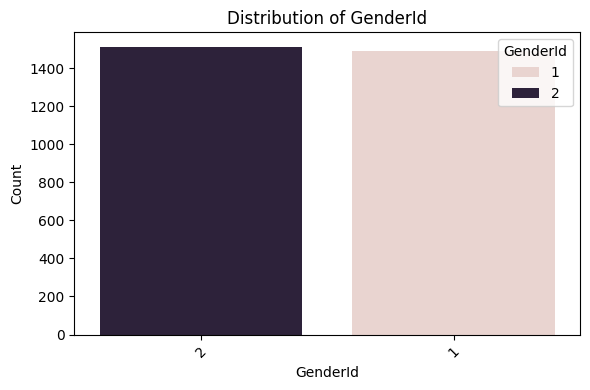

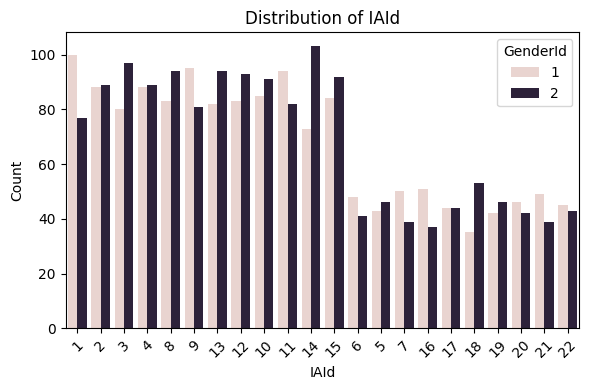

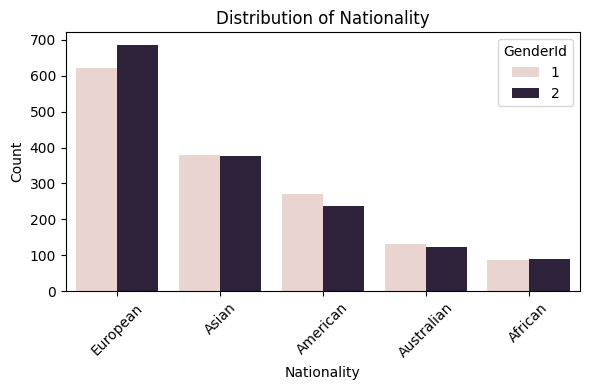

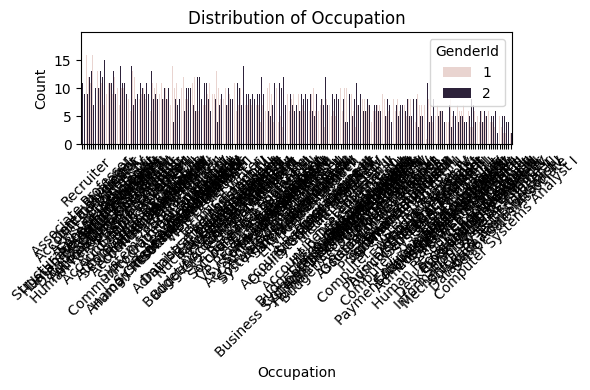

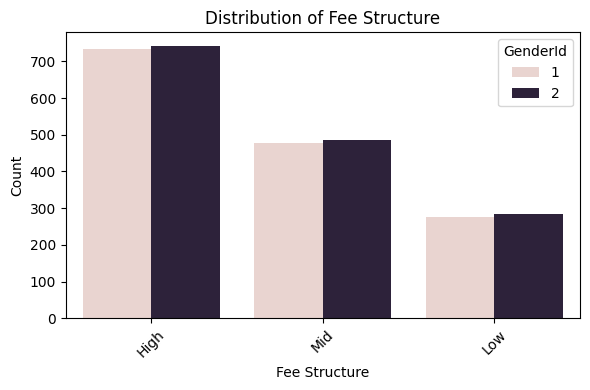

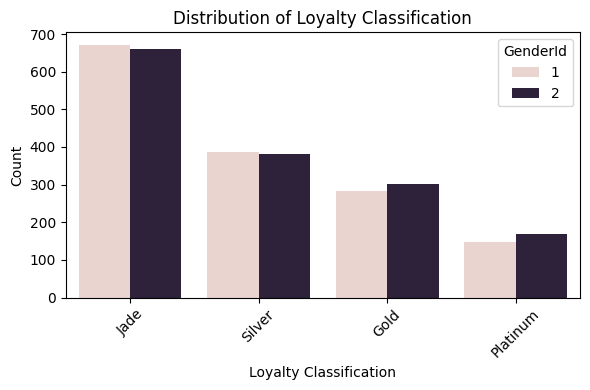

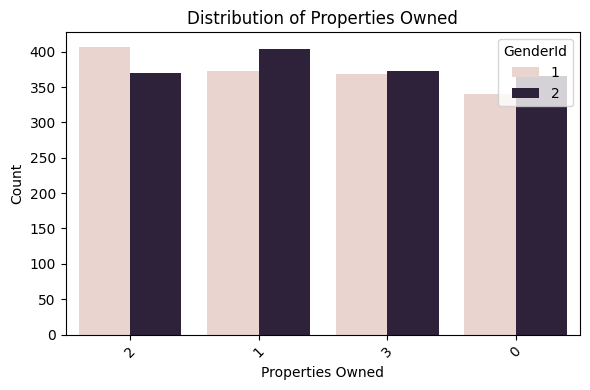

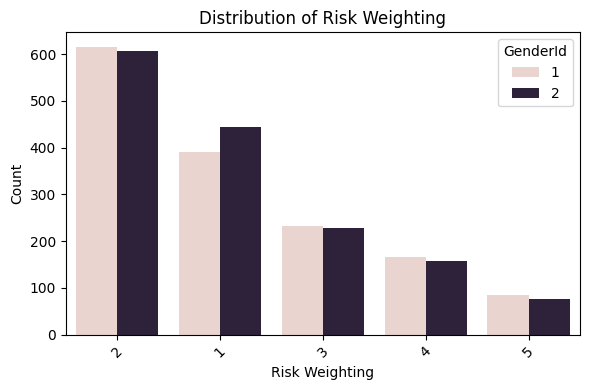

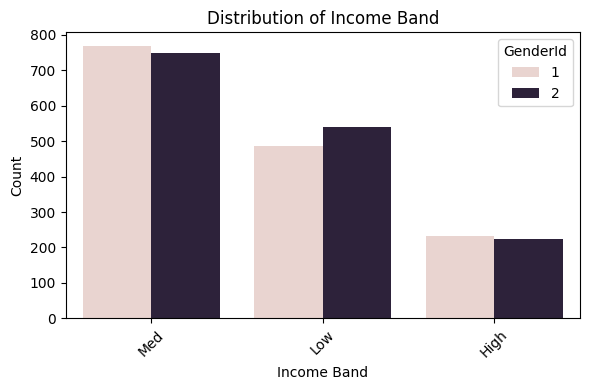

In [62]:
# Examine the distribution of unique categories in each column
for col in categorical_cols:
    if col not in df.columns:
        print(f"Skipping '{col}': column not found")
        continue
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x=col, hue="GenderId", order=df[col].value_counts().index)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

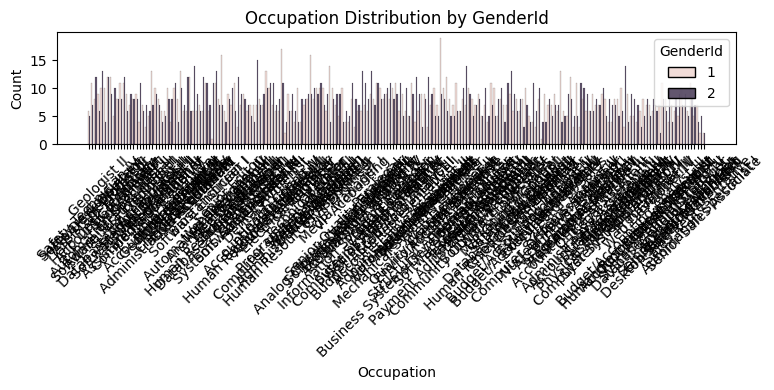

In [63]:
# Histplot For Occupation
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="Occupation", hue="GenderId", multiple="dodge", shrink=0.8)
plt.title("Occupation Distribution by GenderId")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

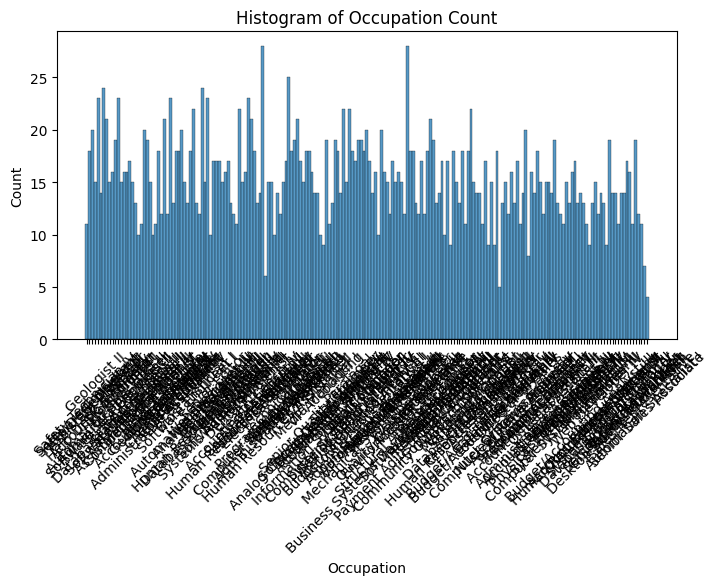

In [64]:
for col in categorical_cols:
    if col == "Occupation":
        plt.figure(figsize=(8, 4))
        sns.histplot(df[col])
        plt.title("Histogram of Occupation Count")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.xticks(rotation=45)
        plt.show()

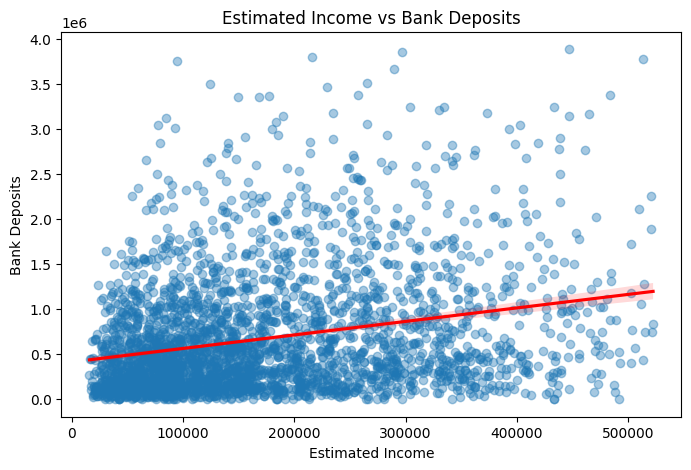

In [65]:
# Numerical Analysis
# Easimate Income vs Bank Deposits
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="Estimated Income", y="Bank Deposits",
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title("Estimated Income vs Bank Deposits")
plt.xlabel("Estimated Income")
plt.ylabel("Bank Deposits")
plt.show()

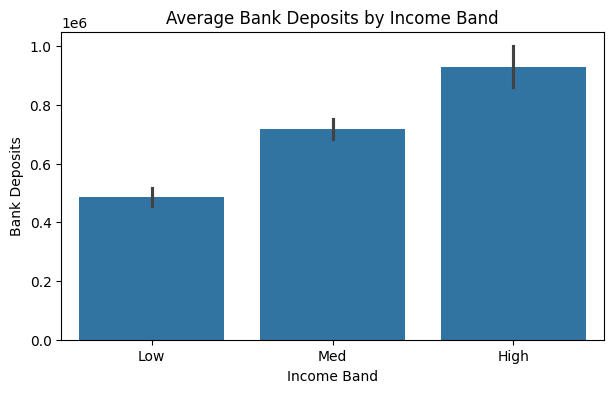

In [66]:
# Average saving According to Income Band
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="Income Band", y="Bank Deposits", order=["Low", "Med", "High"], estimator="mean")
plt.title("Average Bank Deposits by Income Band")
plt.show()

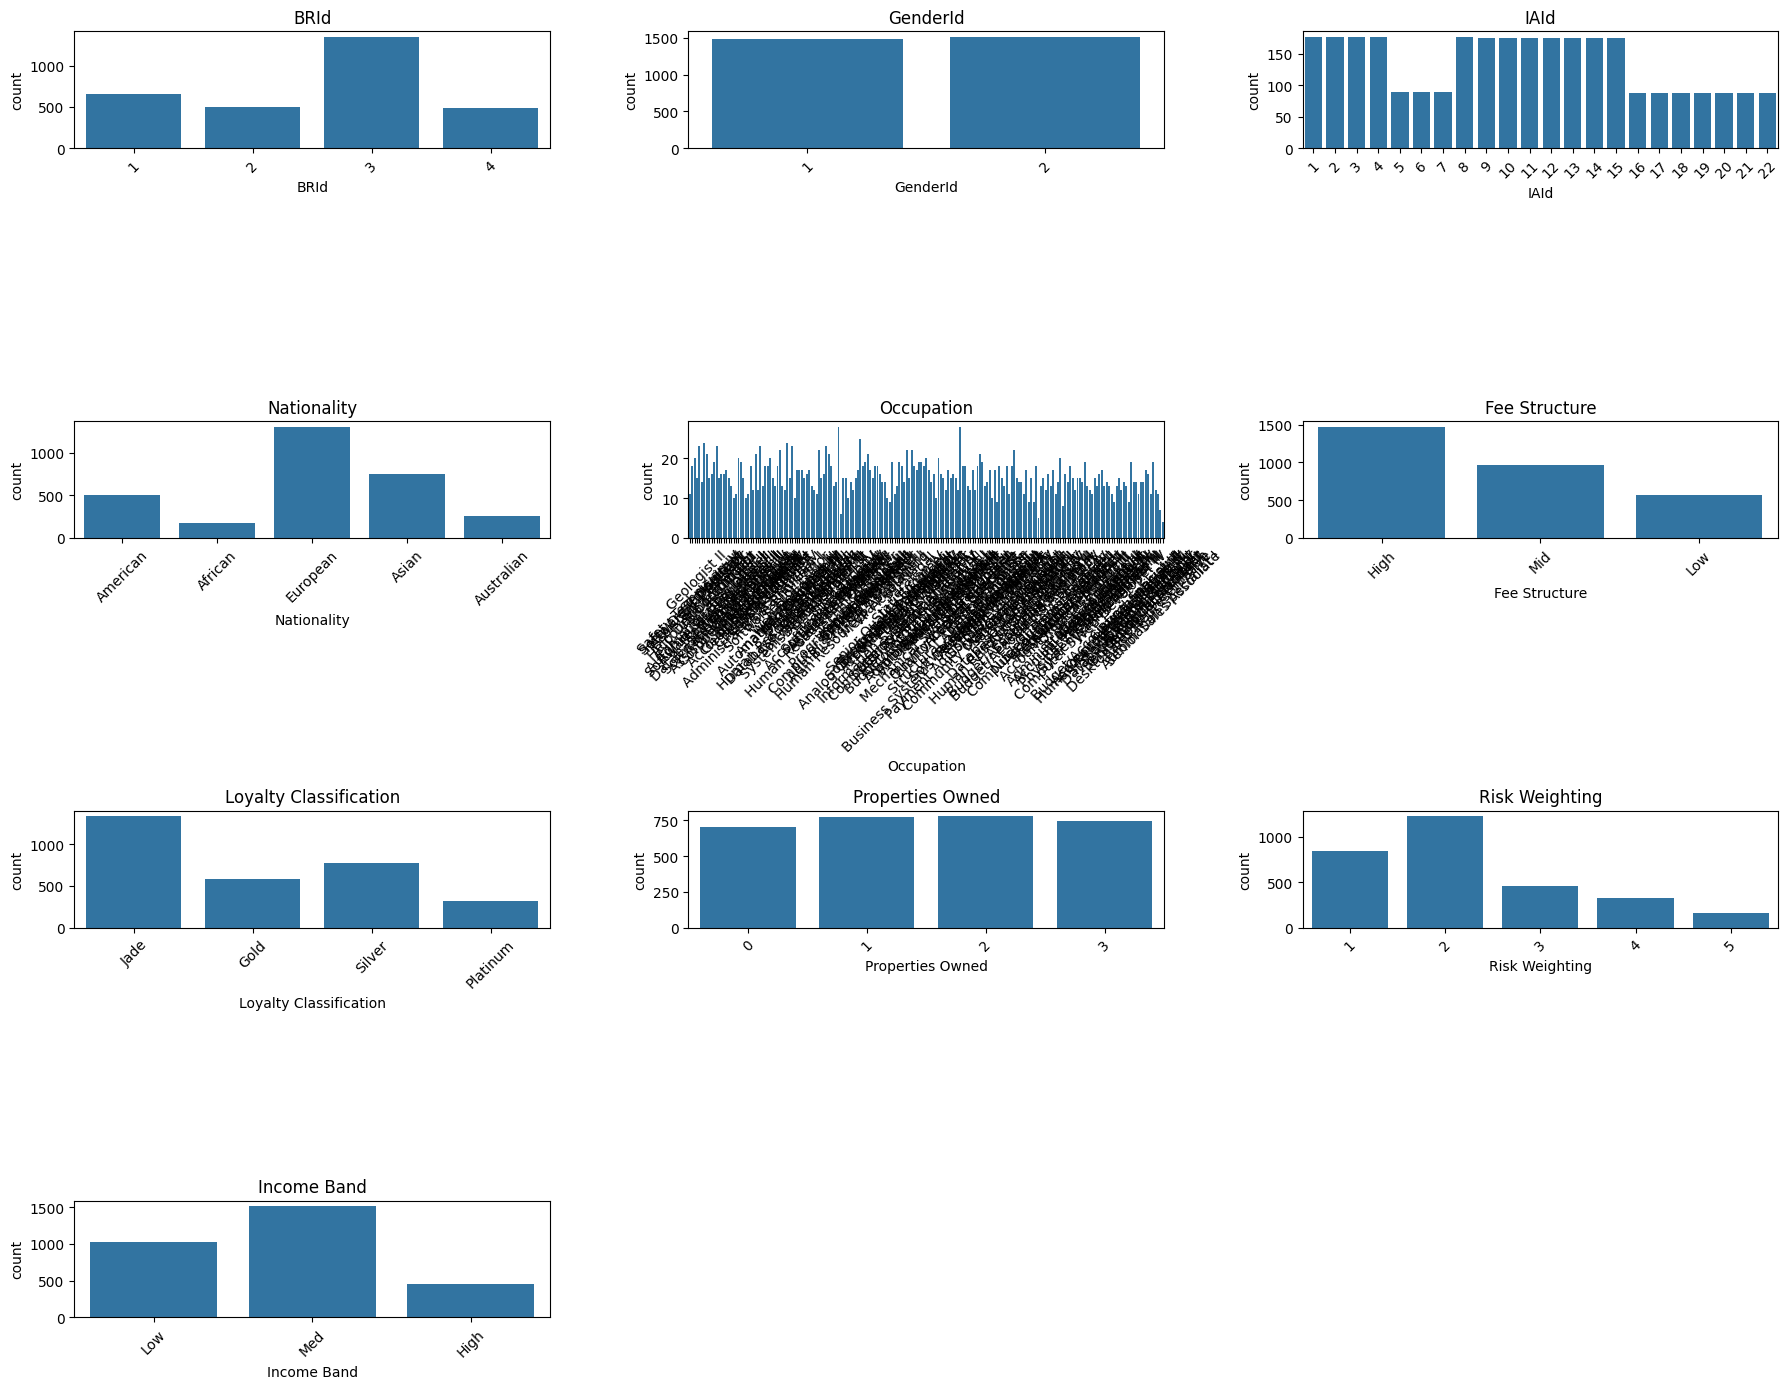

In [67]:
# All In One
categorical_cols = ["BRId", "GenderId", "IAId", "Nationality",
                    "Occupation", "Fee Structure", "Loyalty Classification",
                    "Properties Owned", "Risk Weighting", "Income Band"]

plt.figure(figsize=(18, 14))
for i, col in enumerate(categorical_cols):
    plt.subplot(4, 3, i+1)
    sns.countplot(x=df[col])
    plt.title(col)
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

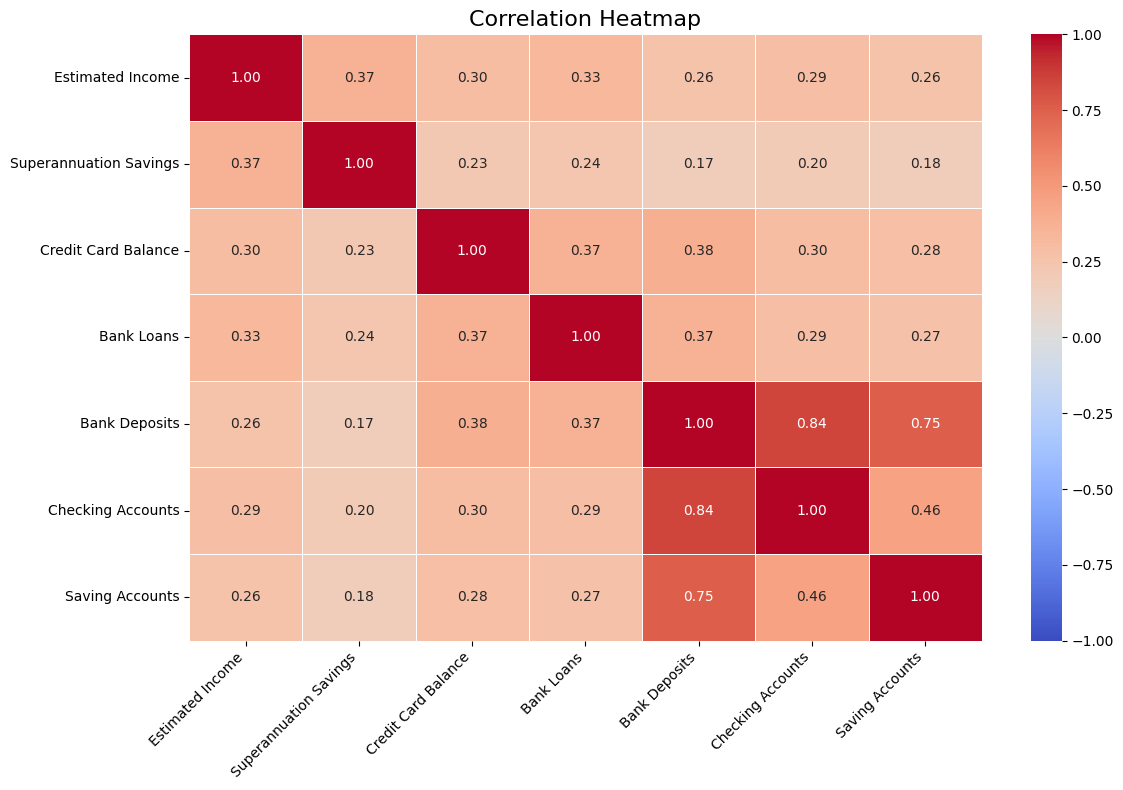

In [68]:
# Coreltion Matrix

numerical_cols = ['Estimated Income', 'Superannuation Savings', 'Credit Card Balance',
                  'Bank Loans', 'Bank Deposits', 'Checking Accounts', 'Saving Accounts']

plt.figure(figsize=(12, 8))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f",
            linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Heatmap", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [69]:
# Shape aur missing values
print("Shape:", df.shape)
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("Duplicates:", df.duplicated().sum())

# Numerical summary
display(df[numerical_cols].describe().T)

# Skewness aur outliers (IQR method)
print("\nSkewness:\n", df[numerical_cols].skew().round(2))
for col in numerical_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {outliers} outliers ({outliers / len(df) * 100:.1f}%)")

# Top correlations (sabse strong pairs)
corr = df[numerical_cols].corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("\nTop correlations:\n", pairs.sort_values(key=abs, ascending=False).head(5).round(2))

# Categorical: sabse zyada common category
for col in ["Occupation", "Nationality", "Loyalty Classification", "Income Band"]:
    if col in df.columns:
        print(f"\n{col}:\n", df[col].value_counts(normalize=True).head(3).round(2) * 100)

# Income Band ke hisaab se average
if "Income Band" in df.columns:
    display(df.groupby("Income Band", observed=True)[numerical_cols].mean().round(0))

Shape: (3000, 26)

Missing values:
 Series([], dtype: int64)
Duplicates: 0


,count,mean,std,min,25%,50%,75%,max
Estimated Income,3000.0,171305.034263,111935.808209,15919.48,82906.5950,142313.480,242290.3050,522330.26
Superannuation Savings,3000.0,25531.599673,16259.950770,1482.03,12513.7750,22357.355,35464.7400,75963.90
Credit Card Balance,3000.0,3176.206943,2497.094709,1.17,1236.6300,2560.805,4522.6325,13991.99
Bank Loans,3000.0,591386.155487,457557.036334,0.00,239628.1375,479793.400,825813.0375,2667556.66
Bank Deposits,3000.0,671560.193923,645716.856875,0.00,204400.3750,463316.460,942754.6300,3890598.08
Checking Accounts,3000.0,321092.949127,282079.553893,0.00,119947.5300,242815.655,434874.9375,1969923.08
Saving Accounts,3000.0,232908.353483,230007.777498,0.00,74794.4050,164086.555,315575.0025,1724118.36



Skewness:
 Estimated Income          0.88
Superannuation Savings    0.71
Credit Card Balance       1.13
Bank Loans                1.18
Bank Deposits             1.71
Checking Accounts         1.73
Saving Accounts           2.19
dtype: float64
Estimated Income: 26 outliers (0.9%)
Superannuation Savings: 19 outliers (0.6%)
Credit Card Balance: 85 outliers (2.8%)
Bank Loans: 85 outliers (2.8%)
Bank Deposits: 149 outliers (5.0%)
Checking Accounts: 138 outliers (4.6%)
Saving Accounts: 155 outliers (5.2%)

Top correlations:
 Bank Deposits        Checking Accounts         0.84
                     Saving Accounts           0.75
Checking Accounts    Saving Accounts           0.46
Credit Card Balance  Bank Deposits             0.38
Estimated Income     Superannuation Savings    0.37
dtype: float64

Occupation:
 Occupation
Associate Professor             1.0
Structural Analysis Engineer    1.0
Recruiter                       1.0
Name: proportion, dtype: float64

Nationality:
 Nationality
Europe

,Estimated Income,Superannuation Savings,Credit Card Balance,Bank Loans,Bank Deposits,Checking Accounts,Saving Accounts
Income Band,,,,,,,
Low,64689.0,18793.0,2349.0,436410.0,486223.0,231433.0,170391.0
Med,182132.0,27291.0,3345.0,621286.0,719400.0,341785.0,246008.0
High,375405.0,34854.0,4478.0,840951.0,929822.0,454186.0,330129.0


***Insights***

The dataset covers 3,000 bank customers across 26 columns and is clean, with no missing values or duplicates. Most customers are middle-income (51% Med band), and the distributions of income, deposits, loans and savings are right-skewed. A small group of wealthy customers pulls the averages up. Those outliers (up to 5% in the savings and deposit columns) look like genuine high-value customers, so they should be kept and studied as their own segment.

***Key findings***

Income vs. balances: Deposits, loans and credit card balances all rise with income, but deposits grow much more slowly than income (High band has about 5.8x the income of Low but only about 1.9x the deposits).
Strongest relationships: Bank Deposits is closely tied to Checking Accounts (0.84) and Saving Accounts (0.75). Income alone is a weak predictor of deposits.
Customer base: 44% European, 44% in the lowest loyalty tier (Jade), and Occupation has too many unique values to use without grouping.